# Reading a trap array: which numbers say it is good

**Question:** Which numbers say whether a trap array is good, how do efficiency, uniformity, relative spread and the power budget disagree on the same hologram, and what does each one hide?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (where the light goes)
- **Reading time:** about 45 minutes

## Objectives

A hologram is judged by the traps it makes. For an array of a hundred traps the judgement has to be a handful of numbers, and each number answers a different question: how much of the light reached the traps, how alike the traps are, how far the worst one is from the rest, and where the rest of the light went. You will compute all of them on a ten by ten array for three holograms of increasing quality, build a case in which two of them rank two holograms in opposite order, see how target weights change what uniform means, and measure how the power budget depends on a radius that the analyst chooses.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m01_superposition, m04_gs, m06_gsw

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence.
- File read: `data/examples/cases.json`, case C12, a square array of 10 by 10 traps (100 traps, 7.97 um apart) on the 256 by 256 pixel SLM of the earlier notebook, with a 30 iteration budget and the seed 20261028.

In [2]:
# case C12: a square array of 10 x 10 traps, the array of the published comparison
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C12_calibration"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
pitch_um = np.diff(np.unique(traps.x_m))[0] * 1e6
print(f"{len(traps)} traps, spacing {pitch_um:.2f} um, SLM {setup.n_pix} x {setup.n_pix}")
print(f"iterations in the budget: {rec['budget']['iterations']}, seed {rec['seed']}")

100 traps, spacing 7.97 um, SLM 256 x 256
iterations in the budget: 30, seed 20261028


## Method

Let $I_m = |V_m|^2$ be the fraction of the input power in the peak of trap $m$ (notebook 01). Three numbers summarize the array. The efficiency is $e = \sum_m I_m$. The uniformity is $u = 1 - (\max I - \min I)/(\max I + \min I)$, which is 1 for equal traps (Di Leonardo et al. 2007, Eq. 4, https://doi.org/10.1364/OE.15.001913; Polin et al. 2005, https://doi.org/10.1364/OPEX.13.005831, print the same ratio without the leading $1 -$, which is a non-uniformity, and the two must not be mixed). The relative spread is $\sigma = 100\,\mathrm{std}(I)/\mathrm{mean}(I)$ in percent. Traps matter through their depth, which is proportional to intensity, so a spread of the intensities is a spread of the trap depths: Manetsch et al. 2025 (https://arxiv.org/abs/2403.12021) report an 11.4 percent depth spread after weighted Gerchberg-Saxton in an array of about 12,000 tweezers. A fourth quantity, the power budget, integrates the focal power instead of reading peaks. The steps below compute all of them for three methods, break them on purpose, and read them again.

First the holograms. The superposition of prisms and lenses (M01) has no iteration, plain Gerchberg-Saxton (M04) iterates with the amplitude fixed to the target, and weighted Gerchberg-Saxton (M06) also reweights the traps; the next notebooks derive them, and here they are three arrays of different quality. The cell runs each one for the 30 iterations of the case and prints its three numbers, read from the trap fields `res.fields` that every method returns.

In [3]:
# three holograms of the same array: the superposition, plain Gerchberg-Saxton and weighted Gerchberg-Saxton
budget = Budget(rec["budget"]["iterations"])
runs = {}
runs["M01"] = m01_superposition.run(setup, target, budget=budget, rng=Rng(rec["seed"]))
runs["M04"] = m04_gs.run(setup, target, budget=budget, rng=Rng(rec["seed"]))
runs["M06"] = m06_gsw.run(setup, target, budget=budget, rng=Rng(rec["seed"]))
for name, res in runs.items():
    i = metrics.trap_intensities(res.fields)
    e, u, sigma = metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)
    print(f"{name}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

M01: e = 0.3280, u = 0.0003, sigma = 268.79 %
M04: e = 0.8174, u = 0.5064, sigma = 19.97 %
M06: e = 0.8074, u = 0.9670, sigma = 1.13 %


Do the numbers always agree? They answer different questions, and uniformity depends only on the brightest and the dimmest trap. To see the consequence, take the M06 hologram, which is nearly perfect, and dim one trap to 20 percent of its power, as if it had been blocked or mispositioned. Then put that array next to the plain Gerchberg-Saxton one. The cell prints $u$, $\sigma$ and $e$ for both.

In [4]:
# the same two metrics on a hologram of GS with one trap dimmed to 20 percent of its power
base = metrics.trap_intensities(runs["M04"].fields)
gsw = metrics.trap_intensities(runs["M06"].fields)
spoiled = gsw.copy()
spoiled[37] *= 0.2
for label, vec in (('M04, plain GS', base), ('M06 with one trap at 20 percent', spoiled)):
    u, sigma, e = metrics.uniformity(vec), metrics.rel_std(vec), metrics.efficiency(vec)
    print(f"{label}: u = {u:.4f}, sigma = {sigma:.2f} %, e = {e:.4f}")
print(f"weakest trap over the mean of the dimmed array: {spoiled.min() / spoiled.mean():.2f}")

M04, plain GS: u = 0.5064, sigma = 19.97 %, e = 0.8174
M06 with one trap at 20 percent: u = 0.3258, sigma = 8.10 %, e = 0.8010
weakest trap over the mean of the dimmed array: 0.20


The next figure sorts the power of every trap, relative to the mean, for the three holograms and for the dimmed array, on a logarithmic axis.

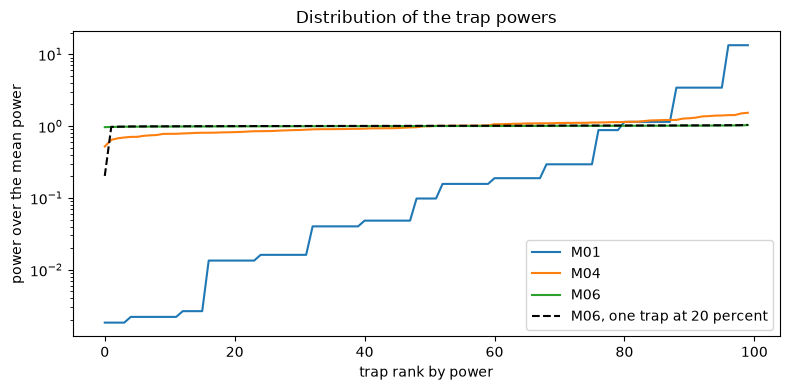

In [5]:
# every trap's power relative to the mean, sorted, for the three holograms and the dimmed one
fig, ax = plt.subplots(figsize=(8, 4))
for name, res in runs.items():
    i = metrics.trap_intensities(res.fields)
    ax.semilogy(np.sort(i / i.mean()), label=name)
ax.semilogy(np.sort(spoiled / spoiled.mean()), "k--", label="M06, one trap at 20 percent")
ax.set_xlabel("trap rank by power")
ax.set_ylabel("power over the mean power")
ax.set_title("Distribution of the trap powers")
ax.legend()
fig.tight_layout()
plt.show()

The superposition has traps more than three orders of magnitude apart, and the steps are the symmetry of the lattice: traps that the geometry treats alike get exactly the same power. Gerchberg-Saxton is a smooth ramp from about 0.5 to about 1.6 of the mean, so every trap is within a factor of three of any other. Weighted Gerchberg-Saxton is flat to the eye, and the dashed curve differs from it at one point only. The ranking by $u$ puts plain Gerchberg-Saxton (0.5064) ahead of the dimmed array (0.3258), because the one dim trap sets the minimum. The ranking by $\sigma$ puts the dimmed array (8.10 percent) ahead of plain Gerchberg-Saxton (19.97 percent), because 99 traps are almost perfect. Neither ranking is wrong; they answer worst trap against typical trap. The figure does not say which array an experiment would prefer: that depends on whether one lost trap ruins the run, as in atom rearrangement, or whether the average depth is what matters.

A target can also ask for unequal traps, with weights $w_m$ that are target intensities; then uniform means $I_m/w_m$ equal, and the metrics are computed on the divided intensities `trap_intensities(v, weights)`. The cell asks M06 for an array whose left five columns have weight 2 and whose right five have weight 1, and prints the metrics on the raw powers and on the powers divided by the weights.

In [6]:
# a target whose left five columns ask for twice the power of the right five columns
heavy = np.array([t.id % 10 < 5 for t in traps])
weighted = Target.from_traps(TrapSet(replace(t, weight=2.0) if h else t for t, h in zip(traps, heavy)))
res_w = m06_gsw.run(setup, weighted, budget=budget, rng=Rng(rec["seed"]))
raw = metrics.trap_intensities(res_w.fields)
scaled = metrics.trap_intensities(res_w.fields, weighted.traps.weight)
for label, vec in (("raw intensities", raw), ("intensities divided by the target weights", scaled)):
    print(f"{label}: u = {metrics.uniformity(vec):.4f}, sigma = {metrics.rel_std(vec):.2f} %")
print(f"mean power of the heavy traps over the light ones: {raw[heavy].mean() / raw[~heavy].mean():.3f}")

raw intensities: u = 0.6513, sigma = 33.17 %
intensities divided by the target weights: u = 0.9764, sigma = 0.80 %
mean power of the heavy traps over the light ones: 1.992


So far every number came from peaks. The power budget instead integrates the focal power $|E|^2/N_{pix}$ of the whole grid and splits it into the power within a radius of each trap (2 bins, one resolution cell, by default), the power within the same radius of the optical axis that is not a trap, and the rest, which is ghosts, tails and the folded replicas. The cell computes the focal field of each hologram and prints the four fractions, which add to 1.

In [7]:
# where the input power goes, from the focal field of each hologram (integrated over discs of 2 bins)
focal = {name: forward.fft_focal_field(res.phi, setup) for name, res in runs.items()}
shares = {name: metrics.power_budget(e, setup, traps) for name, e in focal.items()}
for name, share in shares.items():
    parts = ", ".join(f"{k} {v:.4f}" for k, v in share.items())
    print(f"{name}: {parts}")

M01: traps 0.3517, zero_order 0.0000, ghosts 0.6483, remainder 0.0000
M04: traps 0.8765, zero_order 0.0000, ghosts 0.1235, remainder 0.0000
M06: traps 0.8659, zero_order 0.0000, ghosts 0.1341, remainder 0.0000


The split depends on the radius, which is the analyst's choice and not a property of the hologram. The cell recomputes the budget of M06 for radii from 1 to 8 bins.

In [8]:
# the same split for M06 when the disc around each trap grows from 1 to 8 bins
radii = [1, 2, 3, 4, 6, 8]
sweep = {r: metrics.power_budget(focal["M06"], setup, traps, r) for r in radii}
for r, share in sweep.items():
    print(f"radius {r}: in the trap discs {share['traps']:.4f}, in the ghosts {share['ghosts']:.4f}")

radius 1: in the trap discs 0.6204, in the ghosts 0.3796
radius 2: in the trap discs 0.8659, in the ghosts 0.1341
radius 3: in the trap discs 0.9032, in the ghosts 0.0968
radius 4: in the trap discs 0.9112, in the ghosts 0.0888
radius 6: in the trap discs 0.9204, in the ghosts 0.0796
radius 8: in the trap discs 0.9266, in the ghosts 0.0734


Two fractions are named separately because designers watch them. The zero order is the peak at the optical axis, which an ideal device does not create for this array; the ghost fraction is the share of power outside the trap and axis discs. The cell prints both for each hologram.

In [9]:
# the peak fraction at the zero order and the ghost fraction, one number per hologram
for name, e in focal.items():
    zero = metrics.zero_order_fraction(e, setup)
    ghost = metrics.ghost_fraction(e, setup, traps, 2)
    print(f"{name}: zero-order peak {zero:.5f}, ghost fraction {ghost:.4f}")

M01: zero-order peak 0.00000, ghost fraction 0.6483
M04: zero-order peak 0.00000, ghost fraction 0.1235
M06: zero-order peak 0.00000, ghost fraction 0.1341


The figure shows the budget of the three holograms as stacked bars on the left and the dependence of M06's budget on the disc radius on the right.

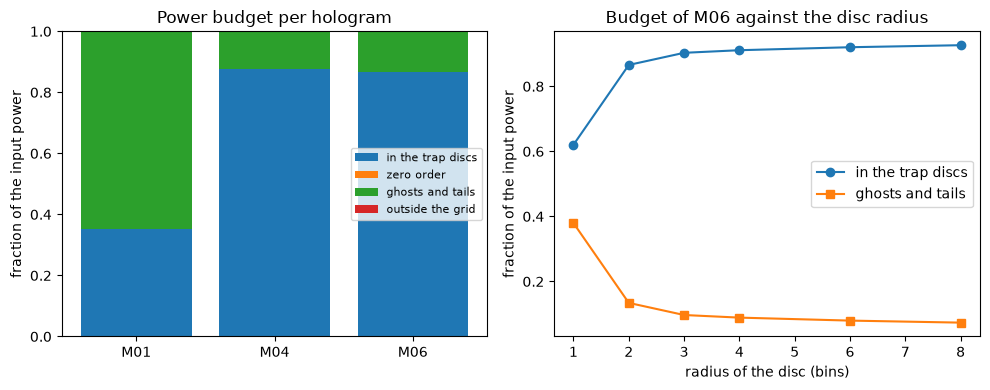

In [10]:
# left: the power budget per hologram; right: the share inside the trap discs against the disc radius
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
bottom = np.zeros(len(shares))
labels = {
    "traps": "in the trap discs",
    "zero_order": "zero order",
    "ghosts": "ghosts and tails",
    "remainder": "outside the grid",
}
for part, label in labels.items():
    values = np.array([share[part] for share in shares.values()])
    ax1.bar(list(shares), values, bottom=bottom, label=label)
    bottom += values
ax1.set_ylabel("fraction of the input power")
ax1.set_title("Power budget per hologram")
ax1.legend(loc="center right", fontsize=8)
ax2.plot(radii, [sweep[r]["traps"] for r in radii], "o-", label="in the trap discs")
ax2.plot(radii, [sweep[r]["ghosts"] for r in radii], "s-", label="ghosts and tails")
ax2.set_xlabel("radius of the disc (bins)")
ax2.set_ylabel("fraction of the input power")
ax2.set_title("Budget of M06 against the disc radius")
ax2.legend()
fig.tight_layout()
plt.show()

Plain and weighted Gerchberg-Saxton place 0.8765 and 0.8659 of the input power inside the trap discs, against 0.3517 for the superposition, which sends 0.6483 into ghosts. Weighted Gerchberg-Saxton buys uniformity (0.9670 against 0.5064) with 0.0106 of the power in the discs: it is a very good bargain, and one that the peak efficiency reports as 0.8074 against 0.8174. On the right, the share inside the discs grows from 0.6204 at one bin to 0.8659 at two and 0.9266 at eight, because a wider disc keeps more of each spot's tail, and the ghost share falls from 0.3796 to 0.0734. A budget therefore has to be quoted with its radius. The zero order and the outside-the-grid fractions are exactly zero here: the ideal device has no dead area and no nonlinearity, so those two bars are empty by construction and only a device model fills them, as the previous notebook showed.

The last figure looks at where the ghosts are, drawing the focal power of the superposition and of M06 on a log scale with a circle on each trap bin.

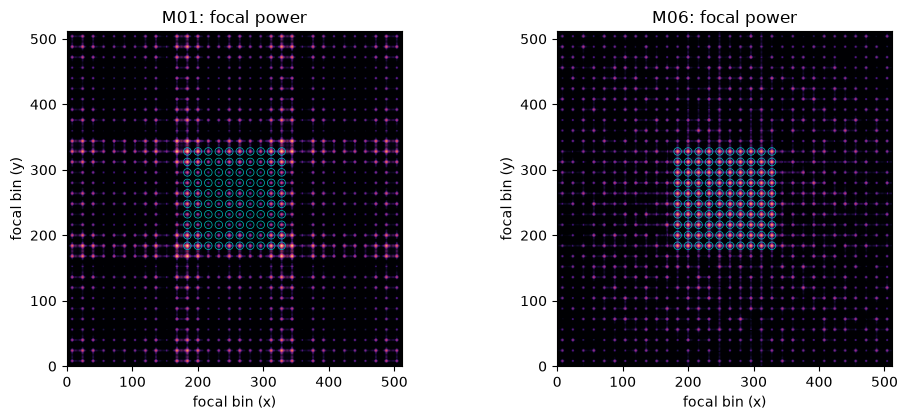

In [11]:
# the focal plane of the superposition and of weighted GS on a log scale, the trap bins marked
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
iy, ix = forward.trap_bins(setup, traps)
for ax, name in zip(axes, ("M01", "M06")):
    power = np.abs(focal[name]) ** 2 * setup.pad**2 / setup.n_pix**2
    ax.imshow(np.log10(power + 1e-9), origin="lower", vmin=-7, vmax=-1, cmap="magma")
    ax.scatter(ix, iy, s=30, facecolors="none", edgecolors="c", linewidths=0.5)
    ax.set_title(f"{name}: focal power")
    ax.set_xlabel("focal bin (x)")
    ax.set_ylabel("focal bin (y)")
fig.tight_layout()
plt.show()

The ghosts of the superposition are not scattered: they sit on rows and columns that continue the lattice of traps, which are the diffraction orders of a periodic array, and in this hologram they carry nearly twice the power of the traps (0.6483 against 0.3517). Weighted Gerchberg-Saxton has the same lattice of faint orders, but they carry 0.1341 of the power instead of 0.6483, and the rest is concentrated in the circled bins. What the figure cannot show is whether a ghost matters: a ghost that falls on an empty region is harmless for a bead, and one that falls on a trap site is a defect; the budget alone cannot tell the two apart.

## Results

**Answer:** Four numbers read a trap array, and they answer four questions. On C12 the superposition reaches an efficiency of 0.3280 and a uniformity of 0.0003, with 0.6483 of the power in ghosts; plain Gerchberg-Saxton reaches 0.8174, 0.5064 and a spread of 19.97 percent; weighted Gerchberg-Saxton reaches 0.8074, 0.9670 and 1.13 percent. The metrics can disagree: with one trap dimmed to 20 percent, a nearly perfect array has a uniformity of 0.3258 and a spread of 8.10 percent, and it ranks below plain Gerchberg-Saxton by $u$ and above it by $\sigma$. With target weights, the raw uniformity of 0.6513 becomes 0.9764 once the powers are divided by the weights. The budget is a function of the radius: the share in the trap discs is 0.6204 at 1 bin and 0.9266 at 8 bins, so every budget must be quoted with its radius.

## Summary

Efficiency says how much light reaches the traps, uniformity says how bad the worst trap is, the relative spread says how alike the typical traps are, and the power budget says where the rest of the light went. None of them replaces the others, and uniformity is the harshest because one weak trap sets it. A fair report gives at least the efficiency, the uniformity and the spread, states the radius of the budget, and divides by the weights when the target is not flat. The next topic builds holograms that do not iterate and measures them with exactly these numbers.

## References

- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- Polin, Ladavac, Lee, Roichman and Grier, "Optimized holographic optical traps", Optics Express 13, 5831 (2005), https://doi.org/10.1364/OPEX.13.005831.
- Manetsch et al., "A tweezer array with 6100 highly coherent atomic qubits" (2025), https://arxiv.org/abs/2403.12021.